# Agente em um Labirinto Simples

Este notebook demonstra como criar um agente que navega aleatoriamente em um labirinto. O agente é representado como uma bola vermelha que se move em um tabuleiro 5x5, respeitando obstáculos no caminho.

### Onde estão os conceitos da aula

| Conceito | Neste notebook |
|---|---|
| **Agente** | a bola vermelha |
| **Ambiente** | o labirinto 5×5 com obstáculos |
| **Estado** | a posição do agente `[linha, coluna]` |
| **Ação** | cima, baixo, esquerda ou direita |
| **Política** | **aleatória**: sorteia a ação, sem olhar para nada |
| **Recompensa** | **ainda não existe** — e é por isso que este agente não aprende |

> Ao longo do notebook, procure cada um desses elementos no código.

## 1. Importar Bibliotecas Necessárias

Importamos as bibliotecas necessárias para o desenvolvimento do jogo, incluindo NumPy para manipulação de arrays, matplotlib para gráficos e eventos, e sys para controle do sistema.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import clear_output
import time

## 2. Definir o Ambiente (Labirinto)

Criamos um labirinto 5x5 onde:
- **0** representa caminhos livres (células brancas)
- **1** representa obstáculos (células azuis)

In [2]:
# Definindo o tamanho do ambiente (tabuleiro 2D)
n_rows, n_cols = 5, 5

# Definindo o labirinto (1 para obstáculos, 0 para caminhos livres)
maze = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 0, 0, 0]
])

## 3. Inicializar Matplotlib e Configurar a Janela

Inicializamos o Matplotlib e criamos a janela do jogo com as dimensões apropriadas. Definimos também as cores que serão usadas para desenhar o labirinto e o agente.

In [3]:
# @title Cores e tamanho das células
# Configuração para melhor visualização no Colab
plt.style.use('default')

# Tamanho de cada célula em pixels (para visualização)
cell_size = 50

# Cores (em formato RGB normalizado para matplotlib)
white = (1, 1, 1)
blue = (135/255, 206/255, 250/255)
red = (1, 0, 0)
black = (0, 0, 0)

## 4. Definir Funções de Desenho

Essas funções são responsáveis por desenhar o labirinto e o agente na tela.

In [4]:
# @title Função de desenho do labirinto (rode e siga em frente)
# Função para desenhar o labirinto e o agente
def visualize_maze(agent_position, step=None):
    """
    Desenha o labirinto com o agente usando matplotlib
    """
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    
    # Desenhar o labirinto
    for row in range(n_rows):
        for col in range(n_cols):
            if maze[row, col] == 0:
                color = white
                rect = patches.Rectangle((col, row), 1, 1, linewidth=1, 
                                        edgecolor='black', facecolor=color)
            else:
                color = blue
                rect = patches.Rectangle((col, row), 1, 1, linewidth=1, 
                                        edgecolor='black', facecolor=color)
            ax.add_patch(rect)
    
    # Desenhar o agente (círculo vermelho)
    agent_circle = patches.Circle((agent_position[1] + 0.5, agent_position[0] + 0.5), 
                                 0.3, color=red, zorder=5)
    ax.add_patch(agent_circle)
    
    # Configurar os eixos
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)  # Invertido para corresponder ao array
    ax.set_aspect('equal')
    ax.set_xticks(range(n_cols + 1))
    ax.set_yticks(range(n_rows + 1))
    ax.grid(True, alpha=0.3)
    
    # Título
    if step is not None:
        ax.set_title(f'Agente em um Labirinto - Passo {step}', fontsize=14, fontweight='bold')
    else:
        ax.set_title('Agente em um Labirinto', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

## 5. Definir Funções de Ação e Movimento

O agente escolhe ações aleatoriamente (cima, baixo, esquerda, direita) e atualiza sua posição apenas se a ação for válida (não colidir com obstáculos ou sair do mapa).

In [5]:
# Função para movimentar o agente aleatoriamente
def take_random_action():
    return np.random.choice(['up', 'down', 'left', 'right'])

# Função para atualizar a posição do agente com base na ação
def update_position(current_position, action):
    # 'up' sobe no desenho (linha diminui); 'down' desce (linha aumenta)
    if action == 'up' and current_position[0] > 0 and maze[current_position[0] - 1, current_position[1]] == 0:
        return [current_position[0] - 1, current_position[1]]
    elif action == 'down' and current_position[0] < n_rows - 1 and maze[current_position[0] + 1, current_position[1]] == 0:
        return [current_position[0] + 1, current_position[1]]
    elif action == 'left' and current_position[1] > 0 and maze[current_position[0], current_position[1] - 1] == 0:
        return [current_position[0], current_position[1] - 1]
    elif action == 'right' and current_position[1] < n_cols - 1 and maze[current_position[0], current_position[1] + 1] == 0:
        return [current_position[0], current_position[1] + 1]
    else:
        return current_position

## 6. Configurar Variáveis do Jogo

Definimos o número de passos que o agente dará e a posição inicial do agente no labirinto.

In [6]:
# Número de passos que o agente dará
num_steps = 20

# Definindo a posição inicial do agente
agent_position = [0, 0]

## 7. Loop Principal do Jogo

O loop principal executa o jogo para o número de passos especificado. A cada iteração:
1. O agente escolhe uma ação aleatória
2. A posição do agente é atualizada
3. Informações sobre o movimento são exibidas
4. O labirinto é redesenhado **no mesmo lugar** (uma animação)
5. Passamos para o próximo passo

No fim, o registro completo de todos os passos é impresso.

Passo 19: ação = down   | [2, 2] → [2, 2] (bateu: não saiu do lugar)


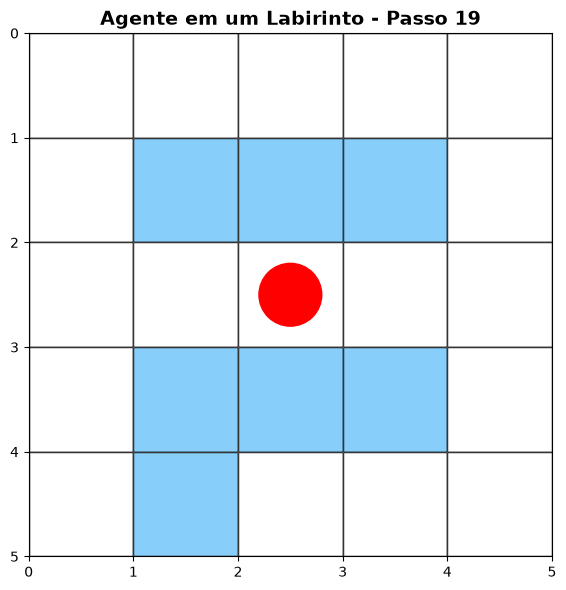

Passo  0: ação = up     | De [0, 0] → [0, 0]  ← bateu, ficou no lugar
Passo  1: ação = right  | De [0, 0] → [0, 1]
Passo  2: ação = down   | De [0, 1] → [0, 1]  ← bateu, ficou no lugar
Passo  3: ação = up     | De [0, 1] → [0, 1]  ← bateu, ficou no lugar
Passo  4: ação = right  | De [0, 1] → [0, 2]
Passo  5: ação = right  | De [0, 2] → [0, 3]
Passo  6: ação = right  | De [0, 3] → [0, 4]
Passo  7: ação = right  | De [0, 4] → [0, 4]  ← bateu, ficou no lugar
Passo  8: ação = down   | De [0, 4] → [1, 4]
Passo  9: ação = right  | De [1, 4] → [1, 4]  ← bateu, ficou no lugar
Passo 10: ação = down   | De [1, 4] → [2, 4]
Passo 11: ação = left   | De [2, 4] → [2, 3]
Passo 12: ação = up     | De [2, 3] → [2, 3]  ← bateu, ficou no lugar
Passo 13: ação = right  | De [2, 3] → [2, 4]
Passo 14: ação = left   | De [2, 4] → [2, 3]
Passo 15: ação = up     | De [2, 3] → [2, 3]  ← bateu, ficou no lugar
Passo 16: ação = up     | De [2, 3] → [2, 3]  ← bateu, ficou no lugar
Passo 17: ação = up     | De [2, 3]

In [7]:
# Loop principal do jogo
np.random.seed(0)  # troque a semente para ver outro passeio

# Criar figura com subplots para cada passo
# Vamos usar uma abordagem que mostra cada passo claramente

steps_data = []  # Armazenar dados de cada passo para análise posterior

for step in range(num_steps):
    # Movimento aleatório do agente
    action = take_random_action()
    previous_position = agent_position.copy()
    agent_position = update_position(agent_position, action)

    # Armazenar dados do passo
    steps_data.append({
        'step': step,
        'action': action,
        'from': previous_position,
        'to': agent_position
    })

    # Animação: apaga o desenho anterior e desenha o passo atual
    clear_output(wait=True)
    bateu = ' (bateu: não saiu do lugar)' if agent_position == previous_position else ''
    print(f"Passo {step:2d}: ação = {action:6s} | {previous_position} → {agent_position}{bateu}")
    visualize_maze(agent_position, step=step)
    time.sleep(0.3)

# Registro completo
for d in steps_data:
    bateu = '  ← bateu, ficou no lugar' if d['from'] == d['to'] else ''
    print(f"Passo {d['step']:2d}: ação = {d['action']:6s} | De {d['from']} → {d['to']}{bateu}")
print()
print("="*60)
print("Simulação Concluída!")
print("="*60)
print(f"Total de passos: {num_steps}")
print(f"Posição inicial: [0, 0]")
print(f"Passos em que bateu num obstáculo ou na borda: {sum(d['from'] == d['to'] for d in steps_data)}")
print(f"Posição final: {agent_position}")

## 8. Visualização em Grid de Todos os Passos

Aqui exibimos uma visualização compacta de todos os passos da simulação em um único grid, permitindo ver a evolução do agente de forma resumida.

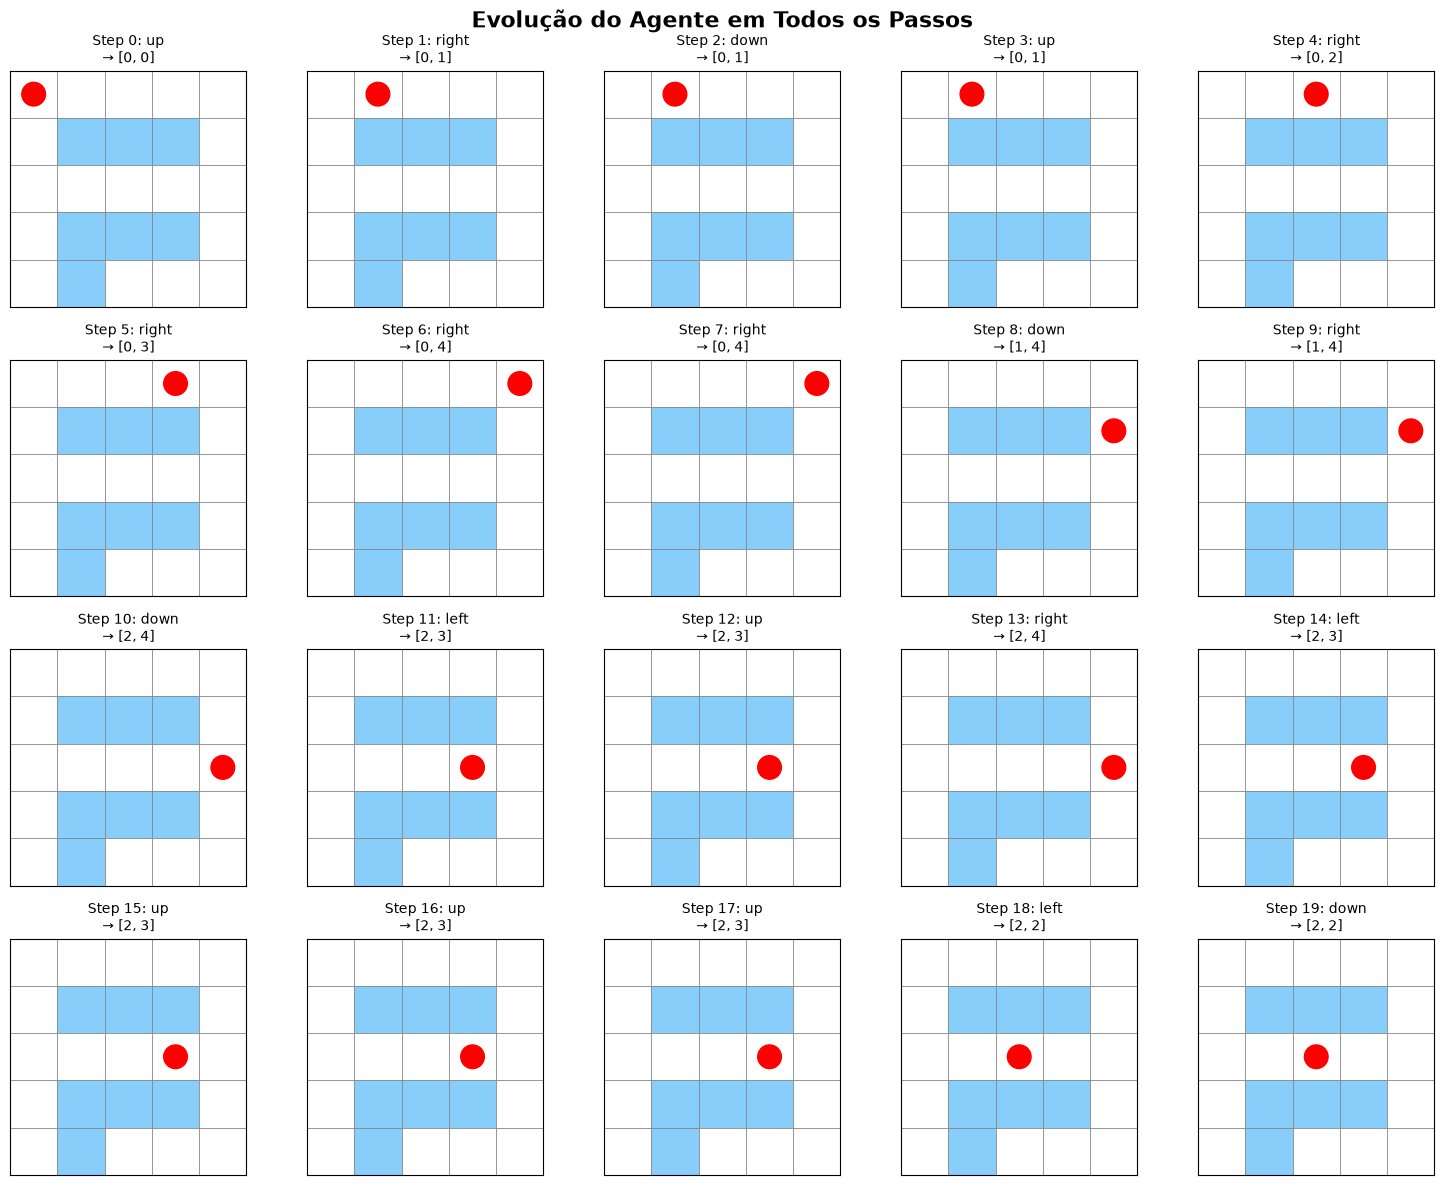

In [8]:
# @title Grade com todos os passos
# Função para visualizar todos os passos em um grid compacto
def visualize_all_steps_grid(steps_data):
    """
    Cria um grid mostrando a evolução do agente em todos os passos
    """
    # Recalcular as posições de cada passo para visualização
    positions = [[0, 0]]  # Posição inicial
    
    for step_data in steps_data:
        positions.append(step_data['to'])
    
    # Calcular número de linhas e colunas para o grid
    num_steps = len(steps_data)
    cols = 5  # 5 colunas
    rows = (num_steps + cols) // cols  # Arredondar para cima
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3*rows))
    axes = axes.flatten()  # Aplanar para facilitar iteração
    
    # Desenhar cada passo
    for idx, (ax, step_data) in enumerate(zip(axes, steps_data)):
        step = step_data['step']
        agent_pos = step_data['to']
        action = step_data['action']
        
        # Desenhar o labirinto
        for row in range(n_rows):
            for col in range(n_cols):
                if maze[row, col] == 0:
                    color = white
                else:
                    color = blue
                rect = patches.Rectangle((col, row), 1, 1, linewidth=0.5, 
                                        edgecolor='gray', facecolor=color)
                ax.add_patch(rect)
        
        # Desenhar o agente
        agent_circle = patches.Circle((agent_pos[1] + 0.5, agent_pos[0] + 0.5), 
                                     0.25, color=red, zorder=5)
        ax.add_patch(agent_circle)
        
        # Configurar os eixos
        ax.set_xlim(0, n_cols)
        ax.set_ylim(n_rows, 0)
        ax.set_aspect('equal')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f'Step {step}: {action}\n→ {agent_pos}', fontsize=10)
    
    # Ocultar axes vazios
    for idx in range(len(steps_data), len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Evolução do Agente em Todos os Passos', fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

# Chamar a função para visualizar todos os passos
visualize_all_steps_grid(steps_data)

## Para pensar

1. **Estado:** quantos estados diferentes existem neste labirinto? (conte as células em que o agente pode estar)
2. **Ação inválida:** o que acontece quando o agente tenta andar contra um obstáculo ou a borda? Quantas vezes isso aconteceu no seu passeio? Isso é bom ou ruim para o agente?
3. **Aprendizado:** este agente fica melhor se rodarmos 1.000 passos em vez de 20? O que falta para ele aprender?
4. **Desafio:** crie uma recompensa — +10 ao chegar em `[4, 4]` e −1 por passo — e some quanto o agente aleatório acumula em 20 passos. Rode várias vezes: o resultado varia muito?

Este agente ainda **não aprende**: falta a recompensa e uma forma de lembrar o que deu certo. É exatamente o que Q-Learning e SARSA vão acrescentar nos próximos exemplos.